### 1.2 Mempelajari driver Neo4j

In [7]:
from neo4j import GraphDatabase, RoutingControl

URI = "bolt://127.0.0.1:7687"
AUTH = ("neo4j", "12345678")

In [8]:
def add_friend(driver, name, friend_name):
    driver.execute_query(
        "MERGE (a:Person {name: $name}) "
        "MERGE (friend:Person {name: $friend_name}) "
        "MERGE (a)-[:KNOWS]->(friend)",
        name=name, friend_name=friend_name, database_="neo4j",
    )

**Pertanyaan Pendahuluan**
1. Database yang dipakai ialah 'neo4j'
2. Untuk akses database lain dalam satu instance, dengan mengganti isi 'database_=', atau menggunakan Cypher ':use <nama database>
3. Graf pertemanannya berarah ('-[KNOWS]->') dengan satu jenis simpul ('Person') dan satu jenis relasi ('KNOWS')

In [9]:
def print_friends(driver, name):
    records, _, _ = driver.execute_query(
        "MATCH (a:Person)-[:KNOWS]->(friend) WHERE a.name = $name "
        "RETURN friend.name ORDER BY friend.name", name=name, database_="neo4j", routing_=RoutingControl.READ,
    )
    for record in records:
        print(record["friend.name"])
with GraphDatabase.driver(URI, auth=AUTH, ) as driver:
    add_friend(driver, "Arthur", "Guinevere")
    add_friend(driver, "Arthur", "Lancelot")
    add_friend(driver, "Arthur", "Merlin")
    print_friends(driver, "Arthur")

Guinevere
Lancelot
Merlin


### 1.3 no. 3: membuat koneksi/session Neo4j


In [13]:
from neo4j import GraphDatabase

uri = "bolt://127.0.0.1:7687"
user = "neo4j"
password = "12345678"

driver = GraphDatabase.driver(uri, auth=(user, password))
session = driver.session(database="system")

### 1.3 no. 4: pengaturan impor

In [ ]:
import os
import pandas as pd
from tqdm import tqdm
from neo4j import GraphDatabase

uri = "bolt://127.0.0.1:7687"
user = "neo4j"
password = "12345678"
source = "data"
LIMIT = None      
batch_size = 10000

**Membaca data dari Kaggle**

Memastikan folder kerja dan file `events.csv` ada di folder `data'.

**Hasil:** folder `data` ketemu dan isinya `events.csv` (plus `train_events.csv` dan `test_events.csv` yang dibuat di sel berikutnya).

In [26]:
import os
print(os.getcwd())
print(os.listdir("data") if os.path.exists("data") else "folder data TIDAK ada")

C:\Users\catri\OneDrive\SaDa Sem 7\GSD
['events.csv', 'test_events.csv', 'train_events.csv']


**Soal 2.1 no. 1 dan 2: filter periode dan simpan ke .csv**

Kolom `timestamp` bentuknya milidetik, jadi diubah dulu ke tanggal (UTC). Setelah itu data dipotong sesuai dua periode di atas. Batas akhirnya dihitung inklusif, makanya kodenya pakai `< 2015-07-16` dan `< 2015-08-09`. Hasil potongan disimpan jadi dua file .csv.

**Hasil:** data asli ada dari 3 Mei sampai 18 September 2015. Setelah difilter, train ada **1.300.890 baris** dan test **342.343 baris**.

In [27]:
df = pd.read_csv("data/events.csv")
df["dt"] = pd.to_datetime(df["timestamp"], unit="ms", utc=True)
print(df["dt"].min(), df["dt"].max())

train = df[(df.dt >= pd.Timestamp("2015-05-15", tz="UTC")) &
           (df.dt <  pd.Timestamp("2015-07-16", tz="UTC"))]
test  = df[(df.dt >= pd.Timestamp("2015-07-24", tz="UTC")) &
           (df.dt <  pd.Timestamp("2015-08-09", tz="UTC"))]
print(len(train), len(test))

train.drop(columns="dt").to_csv("data/train_events.csv", index=False)
test.drop(columns="dt").to_csv("data/test_events.csv", index=False)

2015-05-03 03:00:04.384000+00:00 2015-09-18 02:59:47.788000+00:00
1300890 342343


**Cek user di train dan test (EDA)**


Dihitung berapa user yang muncul di train, di test, dan di dua-duanya. Ini penting buat soal 2.2, karena user yang nggak punya riwayat di train nggak bisa direkomendasikan apa-apa.

**Hasil:** user train 666.256, user test 189.851, dan yang ada di keduanya cuma **11.010** (sekitar 5,8% dari user test).

In [ ]:
train_users = set(train["visitorid"])
test_users = set(test["visitorid"])
print("user di train :", len(train_users))
print("user di test  :", len(test_users))
print("user di keduanya:", len(train_users & test_users))

**Cek item test dan riwayat user irisan (EDA)**


Dari 11.010 user yang ada di dua periode, dicek berapa persen item test-nya yang juga ada di train, dan seberapa banyak riwayat di train.

**Hasil:** dari 36.063 interaksi test milik user irisan, **87,2%** itemnya ada di train, jadi rekomendasi masih memungkinkan. Tapi riwayat user irisan tipis: median cuma 2 interaksi, dan maksimumnya 3.431 (outlier).

In [28]:
both = train_users & test_users
train_items = set(train["itemid"])
test_both = test[test.visitorid.isin(both)]

print("interaksi test dari user irisan:", len(test_both))
print("persen yang itemnya ada di train:", test_both.itemid.isin(train_items).mean())
print(train[train.visitorid.isin(both)].groupby("visitorid").size().describe())

interaksi test dari user irisan: 36063
persen yang itemnya ada di train: 0.8720849624268641
count    11010.000000
mean         6.664214
std         46.776545
min          1.000000
25%          1.000000
50%          2.000000
75%          4.000000
max       3431.000000
dtype: float64


**1.3 no. 5: fungsi impor ke Neo4j**


Dua fungsi dari soal:
- `create_constraints`: bikin constraint unik buat `Visitor` (visitorId) dan `Item` (itemId) biar nggak ada node dobel.
- `import_batch`: bikin node `Visitor` dan `Item` lalu relasinya sesuai kolom `event`: `view` jadi `VIEWED`, `addtocart` jadi `ADDED_TO_CART`, `transaction` jadi `BOUGHT`.

In [29]:
def create_constraints(session):
    session.run("CREATE CONSTRAINT visitor_id IF NOT EXISTS FOR (v:Visitor) REQUIRE v.visitorId IS UNIQUE")
    session.run("CREATE CONSTRAINT item_id IF NOT EXISTS FOR (i:Item) REQUIRE i.itemId IS UNIQUE")

def import_batch(tx, batch):
    cypher_query = """
    UNWIND $batch AS row
    MERGE (v:Visitor {visitorId: row.visitorid})
    MERGE (i:Item {itemId: row.itemid})
    WITH v, i, row
    CALL {
        WITH v, i, row
        WITH v, i, row WHERE row.event = 'view'
        CREATE (v)-[:VIEWED {timestamp: row.timestamp}]->(i)
        UNION ALL
        WITH v, i, row
        WITH v, i, row WHERE row.event = 'addtocart'
        CREATE (v)-[:ADDED_TO_CART {timestamp: row.timestamp}]->(i)
        UNION ALL
        WITH v, i, row
        WITH v, i, row WHERE row.event = 'transaction'
        CREATE (v)-[:BOUGHT {timestamp: row.timestamp, transactionId: row.transactionid}]->(i)
    }
    """
    tx.run(cypher_query, batch=batch)

In [30]:
with GraphDatabase.driver(uri, auth=(user, password)) as d:
    r, _, _ = d.execute_query("MATCH (n) RETURN count(n) AS n", database_="neo4j")
    print("jumlah node sekarang:", r[0]["n"])

jumlah node sekarang: 0


**1.3 no. 4: impor train ke Neo4j**


Baca `train_events.csv` per batch (131 batch) lalu dikirim ke Neo4j lewat `import_batch`.

**Hasil:** impor selesai ("Proses impor berhasil"). Peringatan *deprecated* dari Neo4j soal `CALL` subquery cuma peringatan sintaks, datanya tetap masuk.

In [36]:
csv_file_path = os.path.join(source, "train_events.csv")
assert os.path.exists(csv_file_path), f"{csv_file_path} tidak ditemukan"

driver = GraphDatabase.driver(uri, auth=(user, password))
driver.verify_connectivity()

total_rows = LIMIT if LIMIT else len(train)
total_chunks = (total_rows // batch_size) + 1

with driver.session(database="neo4j") as session:
    create_constraints(session)
    chunks = pd.read_csv(csv_file_path, chunksize=batch_size, nrows=LIMIT)
    for chunk in tqdm(chunks, total=total_chunks, desc="Mengimpor Batch Data"):
        chunk["transactionid"] = chunk["transactionid"].astype("Int64").astype(str).replace("<NA>", "")
        session.execute_write(import_batch, chunk.to_dict(orient="records"))

driver.close()
print("Proses impor berhasil.")

Mengimpor Batch Data: 100%|██████████| 131/131 [03:32<00:00,  1.62s/it]

Proses impor berhasil.


Verifikasi hasil impor: hitung jumlah node dan relasi di graf.

**Hasil:** 666.256 Visitor dan 170.266 Item. Relasi: 1.258.912 VIEWED + 31.555 ADDED_TO_CART + 10.423 BOUGHT = **1.300.890**, sama persis dengan jumlah baris train.

In [37]:
with GraphDatabase.driver(uri, auth=(user, password)) as d:
    nodes, _, _ = d.execute_query("MATCH (n) RETURN labels(n)[0] AS label, count(*) AS jumlah", database_="neo4j")
    rels, _, _ = d.execute_query("MATCH ()-[r]->() RETURN type(r) AS tipe, count(*) AS jumlah", database_="neo4j")

print("NODE:", [(r["label"], r["jumlah"]) for r in nodes])
print("RELASI:", [(r["tipe"], r["jumlah"]) for r in rels])

NODE: [('Visitor', 666256), ('Item', 170266)]
RELASI: [('VIEWED', 1258912), ('ADDED_TO_CART', 31555), ('BOUGHT', 10423)]


Cek `transactionId` di relasi `BOUGHT` tersimpan sebagai angka biasa, bukan "11220.0".

**Hasil:** nilainya `11220`, `17277`, `4000`, `2045`, `1987`, tanpa `.0`, jadi konversi `Int64` tadi berhasil.

In [33]:
with GraphDatabase.driver(uri, auth=(user, password)) as d:
    r, _, _ = d.execute_query(
        "MATCH ()-[b:BOUGHT]->() RETURN b.transactionId AS tid LIMIT 5",
        database_="neo4j")
    print([x["tid"] for x in r])

['11220', '17277', '4000', '2045', '1987']


In [34]:
with GraphDatabase.driver(uri, auth=(user, password)) as d:
    d.execute_query("MATCH (n) DETACH DELETE n", database_="neo4j")
    r, _, _ = d.execute_query("MATCH (n) RETURN count(n) AS n", database_="neo4j")
    print("jumlah node:", r[0]["n"])   # harus 0

jumlah node: 0


**Soal 2.1 no. 3: komposisi subgraph**


Dua query Cypher lewat Python API:
- `MATCH (n) RETURN labels(n)[0], count(n)`: ambil semua simpul, kelompokkan per label, hitung jumlahnya.
- `MATCH ()-[r]->() RETURN type(r), count(r)`: ambil semua relasi, kelompokkan per jenis, hitung jumlahnya.

**Hasil:** ada 2 jenis simpul: **Visitor 666.256** dan **Item 170.266**. Ada 3 jenis relasi: VIEWED 1.258.912 (sekitar 96,8%), ADDED_TO_CART 31.555, dan BOUGHT 10.423 (sekitar 0,8%).

In [38]:
q_nodes = "MATCH (n) RETURN labels(n)[0] AS label, count(n) AS jumlah"
q_rels  = "MATCH ()-[r]->() RETURN type(r) AS tipe, count(r) AS jumlah"

with GraphDatabase.driver(uri, auth=(user, password)) as d:
    n, _, _ = d.execute_query(q_nodes, database_="neo4j")
    r, _, _ = d.execute_query(q_rels, database_="neo4j")

print(pd.DataFrame([x.data() for x in n]))
print(pd.DataFrame([x.data() for x in r]))

     label  jumlah
0  Visitor  666256
1     Item  170266
            tipe   jumlah
0         VIEWED  1258912
1  ADDED_TO_CART    31555
2         BOUGHT    10423


**Membangun matriks VSM (user x item)**


Graf diubah jadi matriks: baris = user, kolom = item, isinya 1 kalau user pernah berinteraksi sama item itu (view, add to cart, atau beli). Dibuat bentuk *sparse* karena matriks biasa nggak muat di memori. Kalau satu user berinteraksi berkali-kali ke item yang sama, tetap dihitung 1.

**Hasil:** ukuran **666.256 x 170.266** dengan **1.008.624** isian tidak nol. Angkanya lebih kecil dari 1.300.890 relasi karena interaksi berulang di pasangan user-item yang sama digabung jadi satu.

In [39]:
import numpy as np
import scipy.sparse as sp

with GraphDatabase.driver(uri, auth=(user, password)) as d:
    recs, _, _ = d.execute_query(
        "MATCH (v:Visitor)-[r]->(i:Item) RETURN v.visitorId AS u, i.itemId AS i, type(r) AS t",
        database_="neo4j")

edges = pd.DataFrame([x.values() for x in recs], columns=["u", "i", "t"])
u_idx = {u: k for k, u in enumerate(sorted(edges.u.unique()))}
i_idx = {i: k for k, i in enumerate(sorted(edges.i.unique()))}

R = sp.csr_matrix(
    (np.ones(len(edges)), (edges.u.map(u_idx).values, edges.i.map(i_idx).values)),
    shape=(len(u_idx), len(i_idx)))
R.data[:] = 1   # biner: user pernah berinteraksi dengan item (duplikat dijumlah lalu dibinerkan)

print(R.shape, R.nnz)

(666256, 170266) 1008624


**Soal 2.1 no. 4 dan 5: karakteristik VSM User dan VSM Item**


VSM User = tiap user jadi vektor sepanjang jumlah item. VSM Item = tiap item jadi vektor sepanjang jumlah user (matriksnya sama, tinggal ditranspos).

**Hasil:**

| | VSM User | VSM Item |
|---|---|---|
| Shape | 666.256 x 170.266 | 170.266 x 666.256 |
| Dimensi vektor | 170.266 | 666.256 |
| Non-zero per baris (rata-rata / median) | 1,51 / 1 | 5,92 / 2 |
| Maksimum non-zero per baris | 1.826 | 1.473 |
| Jumlah pasangan similarity | 221,9 miliar | 14,5 miliar |

Densitas keduanya sama (0,00089%) karena isinya matriks yang sama. Kalau dibuat matriks biasa butuh sekitar 907 GB, sedangkan sparse cuma sekitar 13 sampai 15 MB.

In [40]:
def describe_vsm(M, nama_baris, nama_kolom):
    n_r, n_c = M.shape
    print(f"Shape            : {M.shape}  ({nama_baris} x {nama_kolom})")
    print(f"Dimensi vektor   : {n_c}")
    print(f"Non-zero         : {M.nnz}")
    print(f"Densitas         : {M.nnz / (n_r*n_c):.8%}")
    print(f"Memori dense     : {n_r*n_c*8/1e9:,.1f} GB (tidak mungkin)")
    print(f"Memori sparse    : {(M.data.nbytes + M.indices.nbytes + M.indptr.nbytes)/1e6:.1f} MB")
    deg = np.diff(M.indptr)
    print(f"Non-zero per baris: mean={deg.mean():.2f}, median={np.median(deg):.0f}, max={deg.max()}")
    print(f"Pasangan similarity penuh: {n_r*(n_r-1)//2:,}")

print("=== VSM USER ===");  describe_vsm(R, "user", "item")
print("\n=== VSM ITEM ==="); describe_vsm(R.T.tocsr(), "item", "user")

=== VSM USER ===
Shape            : (666256, 170266)  (user x item)
Dimensi vektor   : 170266
Non-zero         : 1008624
Densitas         : 0.00088912%
Memori dense     : 907.5 GB (tidak mungkin)
Memori sparse    : 14.8 MB
Non-zero per baris: mean=1.51, median=1, max=1826
Pasangan similarity penuh: 221,948,195,640

=== VSM ITEM ===
Shape            : (170266, 666256)  (item x user)
Dimensi vektor   : 666256
Non-zero         : 1008624
Densitas         : 0.00088912%
Memori dense     : 907.5 GB (tidak mungkin)
Memori sparse    : 12.8 MB
Non-zero per baris: mean=5.92, median=2, max=1473
Pasangan similarity penuh: 14,495,170,245


**Soal 2.1 no. 4 dan 5: plot networkx**


Hanya ambil sampel 12 user (seed 42). Sampelnya diambil dari user yang punya 3 sampai 6 item biar gambarnya kebaca, jadi sampel ini lebih "ramai" daripada user biasa (kebanyakan cuma punya 1 item). Digambar graf bipartit (user-item) dan dua proyeksinya.

**Hasil:**
- Bipartit: 12 user dan 45 item.
- Proyeksi User: 12 simpul dan **0 sisi**. Artinya di sampel ini nggak ada dua user yang punya item yang sama.
- Proyeksi Item: 45 simpul dan **67 sisi**. Bentuknya 12 kelompok kecil, tiap kelompok berisi item milik satu user.

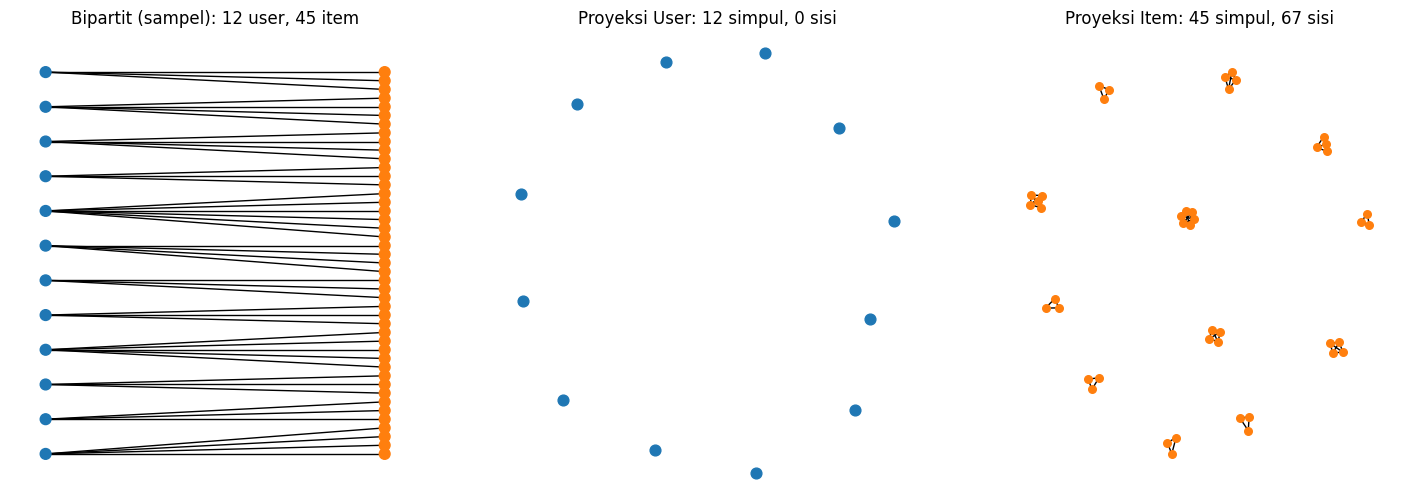

In [42]:
import networkx as nx
import matplotlib.pyplot as plt
from networkx.algorithms import bipartite

rng = np.random.default_rng(42)
deg_u = np.diff(R.indptr)
cand = np.where((deg_u >= 3) & (deg_u <= 6))[0]
samp = rng.choice(cand, 12, replace=False)

B = nx.Graph()
for u in samp:
    for i in R.indices[R.indptr[u]:R.indptr[u+1]]:
        B.add_edge(f"U{u}", f"I{i}")
users = [n for n in B if n.startswith("U")]
items = [n for n in B if n.startswith("I")]

Gu = bipartite.projected_graph(B, users)   # proyeksi User
Gi = bipartite.projected_graph(B, items)   # proyeksi Item

fig, ax = plt.subplots(1, 3, figsize=(18, 6))
nx.draw(B, nx.bipartite_layout(B, users), ax=ax[0], node_size=60,
        node_color=["tab:blue" if n in users else "tab:orange" for n in B], with_labels=False)
ax[0].set_title(f"Bipartit (sampel): {len(users)} user, {len(items)} item")
nx.draw(Gu, ax=ax[1], node_size=60, node_color="tab:blue")
ax[1].set_title(f"Proyeksi User: {Gu.number_of_nodes()} simpul, {Gu.number_of_edges()} sisi")
nx.draw(Gi, ax=ax[2], node_size=30, node_color="tab:orange")
ax[2].set_title(f"Proyeksi Item: {Gi.number_of_nodes()} simpul, {Gi.number_of_edges()} sisi")
plt.show()

**Soal 2.1 no. 6: proyeksi mana yang lebih baik?**


**Proyeksi Item lebih baik**, baik dari sisi efisiensi maupun efektivitas.

- **Efisien:** item (170.266) jauh lebih sedikit daripada user (666.256), jadi pasangan yang harus dibandingkan turun dari 221,9 miliar jadi 14,5 miliar, sekitar 15 kali lebih sedikit.
- **Efektif:** user rata-rata cuma punya 1,51 item (median 1), jadi dua user hampir tidak mempunyai item yang sama. Ini kelihatan di plot: proyeksi User tidak punya sisi sama sekali, sedangkan proyeksi Item punya hubungan antar item. Item punya riwayat lebih banyak (rata-rata 5,92 user per item), jadi kemiripan antar item lebih bisa dipercaya.

**Soal 2.1 no. 7: perhitungan similarity (proyeksi Item)**


Sesuai no. 6, similarity dihitung antar item. Item acuan dipilih acak (seed 42) dari item yang punya 30 sampai 300 user, agar acuannya mempunyai riwayat yang cukup. Mengggunakan Jaccard karena matriksnya biner.

**Hasil:** item acuan **44195** (30 user). Lima item paling mirip punya Jaccard sekitar 0,05 dan masing-masing cuma punya **2 user** yang sama. Jadi kemiripannya nggak kuat, wajar karena kebanyakan item cuma dilihat segelintir user.

In [43]:
Rt = R.T.tocsr()
items_sorted = sorted(i_idx, key=i_idx.get)   # indeks -> itemId
deg_i = np.diff(Rt.indptr)

rng = np.random.default_rng(42)
ref = rng.choice(np.where((deg_i >= 30) & (deg_i <= 300))[0])
ref_id = int(items_sorted[ref])

inter = (Rt @ Rt[ref].T).toarray().ravel()    # jumlah user yang sama
union = deg_i + deg_i[ref] - inter
jac = np.divide(inter, union, out=np.zeros(len(inter)), where=union > 0)
jac[ref] = 0                                   # buang diri sendiri

order = np.lexsort((-inter, -jac))[:5]         # urut jaccard, seri dipecah jumlah user bersama
top5 = [(int(items_sorted[k]), float(jac[k]), int(inter[k])) for k in order]

print("item acuan:", ref_id, "| jumlah user:", deg_i[ref])
for t in top5: print(t)

item acuan: 44195 | jumlah user: 30
(213314, 0.05555555555555555, 2)
(282803, 0.05263157894736842, 2)
(25535, 0.05128205128205128, 2)
(148090, 0.05128205128205128, 2)
(244833, 0.05, 2)


**Soal 2.1 no. 8: kondisi SEBELUM similarity**


Hitung jumlah relasi per jenis sebelum relasi similarity ditulis ke graf.

**Hasil:** VIEWED 1.258.912, ADDED_TO_CART 31.555, BOUGHT 10.423.

In [44]:
with GraphDatabase.driver(uri, auth=(user, password)) as d:
    r, _, _ = d.execute_query("MATCH ()-[r]->() RETURN type(r) AS tipe, count(r) AS jumlah", database_="neo4j")
print("SEBELUM:", [(x["tipe"], x["jumlah"]) for x in r])

SEBELUM: [('VIEWED', 1258912), ('ADDED_TO_CART', 31555), ('BOUGHT', 10423)]


**Soal 2.1 no. 7b: menulis similarity ke graf**


Lima item teratas dihubungkan ke item acuan dengan relasi `SIMILAR_TO`, membawa properti `jaccard` dan `common_users`. Pakai `MERGE` biar nggak dobel kalau dijalankan ulang.

**Hasil:** 5 relasi berhasil ditulis.

In [45]:
q_write = """
MATCH (a:Item {itemId: $ref})
UNWIND $rows AS row
MATCH (b:Item {itemId: row.id})
MERGE (a)-[s:SIMILAR_TO]->(b)
SET s.jaccard = row.score, s.common_users = row.common
"""
rows = [{"id": i, "score": s, "common": c} for i, s, c in top5]

with GraphDatabase.driver(uri, auth=(user, password)) as d:
    d.execute_query(q_write, ref=ref_id, rows=rows, database_="neo4j")
print("tertulis:", len(rows))

tertulis: 5


**Soal 2.1 no. 7a dan 8: top 5**


Query Cypher ngambil 5 relasi `SIMILAR_TO` dari item acuan, diurutkan dari Jaccard terbesar.

**Hasil:** top 5 item: 213314, 282803, 148090, 25535, 244833 (Jaccard 0,056 sampai 0,050, masing-masing 2 user yang sama). Jumlah relasi sesudahnya sama seperti sebelumnya, ditambah **5 relasi SIMILAR_TO**. Jadi similarity masuk ke graf tanpa mengubah data lain.

In [46]:
q_top5 = """
MATCH (a:Item {itemId: $ref})-[s:SIMILAR_TO]->(b:Item)
RETURN b.itemId AS item, s.jaccard AS jaccard, s.common_users AS user_bersama
ORDER BY s.jaccard DESC, s.common_users DESC
LIMIT 5
"""
with GraphDatabase.driver(uri, auth=(user, password)) as d:
    t, _, _ = d.execute_query(q_top5, ref=ref_id, database_="neo4j")
    r, _, _ = d.execute_query("MATCH ()-[r]->() RETURN type(r) AS tipe, count(r) AS jumlah", database_="neo4j")

print(pd.DataFrame([x.data() for x in t]))
print("SESUDAH:", [(x["tipe"], x["jumlah"]) for x in r])

     item   jaccard  user_bersama
0  213314  0.055556             2
1  282803  0.052632             2
2  148090  0.051282             2
3   25535  0.051282             2
4  244833  0.050000             2
SESUDAH: [('VIEWED', 1258912), ('ADDED_TO_CART', 31555), ('BOUGHT', 10423), ('SIMILAR_TO', 5)]


***2.2 Analytics***


**No. 1: pilih user acak**


User dipilih acak pakai `np.random.default_rng(42)` agar hasilnya sama jika dijalankan ulang. Syarat kandidat: ada di train dan test, punya 5 sampai 100 item di train, dan punya minimal satu item test yang ada di train serta belum pernah dilihat user itu. Item yang jadi jawaban benar (ground truth) adalah item test user itu yang memenuhi syarat tadi.

**Hasil:** ada **1.147** kandidat. User terpilih **127747**, punya 7 item di train, ground truth-nya item **94109**.

In [47]:
seen = train.groupby("visitorid")["itemid"].apply(set)
gt_all = test[test.itemid.isin(train_items)].groupby("visitorid")["itemid"].apply(set)

cands = [u for u in sorted(set(both) & set(gt_all.index))
         if 5 <= len(seen[u]) <= 100 and len(gt_all[u] - seen[u]) >= 1]

rng = np.random.default_rng(42)
target_user = rng.choice(cands)
ground_truth = gt_all[target_user] - seen[target_user]

print("user eligible:", len(cands))
print("target_user  :", target_user)
print("item train   :", len(seen[target_user]), "| ground truth:", ground_truth)

user eligible: 1147
target_user  : 127747
item train   : 7 | ground truth: {94109}


**No. 1a dan 1b: KNN item-based dengan k = 5**


Rekomendasi pakai KNN berbasis item, sesuai kesimpulan no. 6. Untuk tiap item yang pernah dilihat user, diambil 5 item tetangga terdekat (Jaccard), skornya dijumlahkan, item yang sudah pernah dilihat dibuang, lalu diambil 5 teratas.

**Hasil:** top 5 rekomendasi: 150748, 94109, 192117, 367265, 229447. **Tiga item yang diiklankan: 150748, 94109, 192117.**

In [48]:
K = 5
u = u_idx[target_user]
my_items = R.indices[R.indptr[u]:R.indptr[u+1]]

inter = (Rt[my_items] @ R).toarray()                       # user bersama: (item user x semua item)
union = deg_i[my_items][:, None] + deg_i[None, :] - inter
jac = np.divide(inter, union, out=np.zeros_like(inter, dtype=float), where=union > 0)
jac[np.arange(len(my_items)), my_items] = 0                # buang diri sendiri

score = np.zeros(Rt.shape[0])
for r in range(len(my_items)):
    top = np.argsort(-jac[r], kind="stable")[:K]
    score[top] += jac[r, top]

score[my_items] = -1                                       # jangan rekomendasikan yang sudah dilihat
rec = np.argsort(-score, kind="stable")[:5]
rec_ids = [int(items_sorted[k]) for k in rec]

print("top-5 rekomendasi :", rec_ids)
print("3 item diiklankan :", rec_ids[:3])

top-5 rekomendasi : [150748, 94109, 192117, 367265, 229447]
3 item diiklankan : [150748, 94109, 192117]


**No. 2: Hit@5 dan NDCG@5**


- **Hit@5**: bernilai 1 kalau ada item benar di 5 rekomendasi teratas, kalau nggak 0.
- **NDCG@5**: mirip Hit@5 tapi urutan diperhitungkan. Item benar di posisi atas dapat nilai lebih besar (diskon 1/log2(posisi + 1)).

**Hasil:** item benar (94109) ada di posisi 2, jadi **Hit@5 = 1** dan **NDCG@5 = 1/log2(3) = 0,6309**.

In [49]:
hits = [1 if i in ground_truth else 0 for i in rec_ids]
hit5 = int(any(hits))
dcg  = sum(h / np.log2(r + 2) for r, h in enumerate(hits))
idcg = sum(1 / np.log2(r + 2) for r in range(min(len(ground_truth), 5)))
ndcg5 = dcg / idcg

print("hits  :", hits)
print("Hit@5 :", hit5)
print("NDCG@5:", round(ndcg5, 4))

hits  : [0, 1, 0, 0, 0]
Hit@5 : 1
NDCG@5: 0.6309
